# Student Dropout Early-Warning System

**Problem statement.** In online courses many students drop out or fail, and teachers usually notice only
when it is too late. This project predicts, from a student's first 60 days of activity, whether they are at
risk, explains the main reasons, and shows teachers which students need help first.

**At risk** = final result *Withdrawn* or *Fail*. **Safe** = *Pass* or *Distinction*.

Data: Kuzilek, J., Hlosta, M. and Zdrahal, Z. (2017). Open University Learning Analytics dataset.
*Scientific Data* 4, 170171. CC BY 4.0.

This notebook runs both in **Google Colab** (reads `oulad.zip` from `My Drive/dropout-project`) and
**locally** (reads `data/download/oulad.zip` next to this notebook). Run the cells top to bottom.

## Phase 2: Load and explore the data

In [1]:
# Cell 1: Connect Google Drive (only when running in Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print('Running in Colab' if IN_COLAB else 'Running locally')

Running locally


In [2]:
# Cell 2: Unzip the data and find the folder with the CSV files automatically
import os, glob, zipfile

if IN_COLAB:
    ZIP = '/content/drive/MyDrive/dropout-project/oulad.zip'
    OUT = '/content/data'
else:
    ZIP = 'data/download/oulad.zip'
    OUT = 'data/oulad'

with zipfile.ZipFile(ZIP) as z:
    z.extractall(OUT)

csvs = sorted(glob.glob(OUT + '/**/studentInfo.csv', recursive=True))
DATA = os.path.dirname(csvs[0]) + '/'   # works even if the zip has a sub-folder
print('DATA =', DATA)
print(sorted(os.path.basename(p) for p in glob.glob(DATA + '*.csv')))

os.makedirs('figures', exist_ok=True)    # plots for the report are saved here

DATA = data/oulad/
['assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


In [3]:
# Cell 3: Load the files (studentVle.csv is big, this takes about a minute)
import pandas as pd

info   = pd.read_csv(DATA + 'studentInfo.csv',         na_values='?')
vle    = pd.read_csv(DATA + 'studentVle.csv',          na_values='?')
sa     = pd.read_csv(DATA + 'studentAssessment.csv',   na_values='?')
assess = pd.read_csv(DATA + 'assessments.csv',         na_values='?')
reg    = pd.read_csv(DATA + 'studentRegistration.csv', na_values='?')

print(info.shape, vle.shape, sa.shape, assess.shape, reg.shape)
info.head()

(32593, 12) (10655280, 6) (173912, 5) (206, 6) (32593, 5)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64
at_risk
1    0.527966
0    0.472034
Name: proportion, dtype: float64


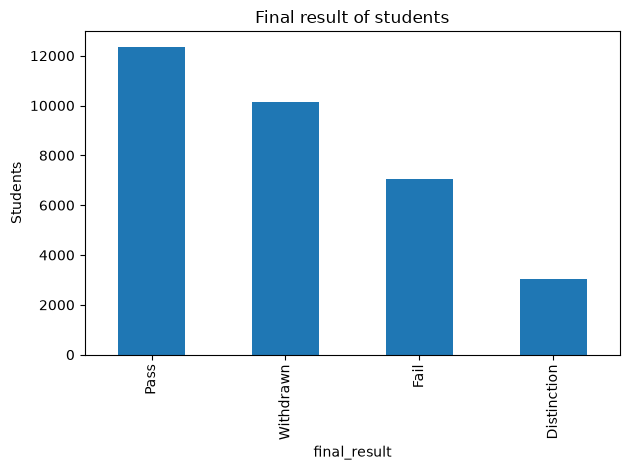

In [4]:
# Cell 4: Create the target and look at it
import matplotlib.pyplot as plt

info['at_risk'] = info['final_result'].isin(['Withdrawn', 'Fail']).astype(int)

print(info['final_result'].value_counts())
print(info['at_risk'].value_counts(normalize=True))

info['final_result'].value_counts().plot(kind='bar', title='Final result of students')
plt.ylabel('Students'); plt.tight_layout()
plt.savefig('figures/01_final_result.png', dpi=150)
plt.show()

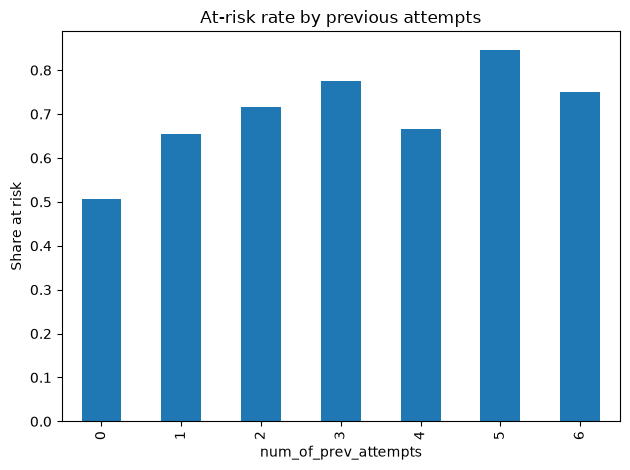

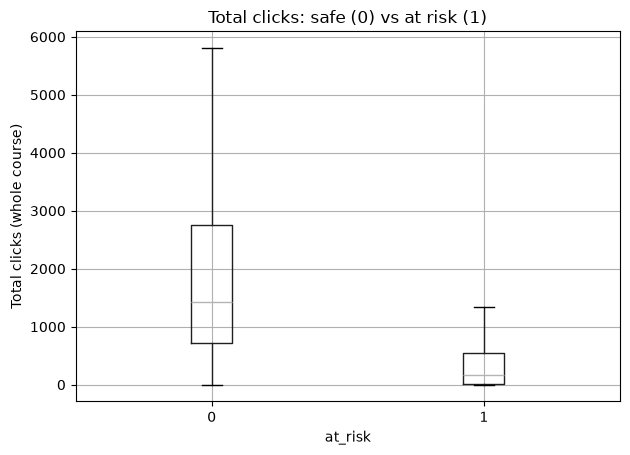

at_risk
0    1425.0
1     175.0
Name: median clicks, dtype: float64


In [5]:
# Cell 5: Two more quick plots
# Risk by previous attempts
info.groupby('num_of_prev_attempts')['at_risk'].mean().plot(
    kind='bar', title='At-risk rate by previous attempts')
plt.ylabel('Share at risk'); plt.tight_layout()
plt.savefig('figures/02_risk_by_prev_attempts.png', dpi=150)
plt.show()

# Total clicks per student vs risk
keys = ['code_module', 'code_presentation', 'id_student']
clicks_all = vle.groupby(keys)['sum_click'].sum().reset_index()
tmp = info.merge(clicks_all, on=keys, how='left').fillna({'sum_click': 0})
tmp.boxplot(column='sum_click', by='at_risk', showfliers=False)
plt.title('Total clicks: safe (0) vs at risk (1)'); plt.suptitle('')
plt.xlabel('at_risk'); plt.ylabel('Total clicks (whole course)'); plt.tight_layout()
plt.savefig('figures/03_clicks_vs_risk.png', dpi=150)
plt.show()

print(tmp.groupby('at_risk')['sum_click'].median().rename('median clicks'))

## Phase 3: Build features from the first 60 days

Only days 0 to 60 are used, so the model sees what a teacher would see two months in (no data leakage).
Students who had already left before day 60 are removed, since they need no prediction.

In [6]:
# Cell 6: Click features
CUTOFF = 60
keys = ['code_module', 'code_presentation', 'id_student']

v = vle[vle['date'] <= CUTOFF]
clicks = v.groupby(keys).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    last_active=('date', 'max')
).reset_index()
clicks['days_inactive'] = CUTOFF - clicks['last_active']
clicks = clicks.drop(columns='last_active')
clicks.head()

,code_module,code_presentation,id_student,total_clicks,active_days,days_inactive
0,AAA,2013J,11391,529,18,6
1,AAA,2013J,28400,669,26,7
2,AAA,2013J,30268,281,12,48
3,AAA,2013J,31604,816,41,0
4,AAA,2013J,32885,605,28,0


In [7]:
# Cell 7: Assignment features
a = sa.merge(assess, on='id_assessment')          # adds module, presentation, deadline
a = a[a['date'] <= CUTOFF]                         # only assignments due by day 60
a['late'] = (a['date_submitted'] > a['date']).astype(int)

scores = a.groupby(keys).agg(
    avg_score=('score', 'mean'),
    num_submitted=('id_assessment', 'count'),
    num_late=('late', 'sum')
).reset_index()
scores.head()

,code_module,code_presentation,id_student,avg_score,num_submitted,num_late
0,AAA,2013J,11391,81.5,2,0
1,AAA,2013J,28400,69.0,2,1
2,AAA,2013J,31604,71.5,2,0
3,AAA,2013J,32885,49.5,2,2
4,AAA,2013J,38053,74.0,2,1


In [8]:
# Cell 8: Join everything into one table
df = info.merge(clicks, on=keys, how='left').merge(scores, on=keys, how='left')

# Students with no activity: fill sensible values
df[['total_clicks', 'active_days', 'num_submitted', 'num_late']] = \
    df[['total_clicks', 'active_days', 'num_submitted', 'num_late']].fillna(0)
df['days_inactive'] = df['days_inactive'].fillna(CUTOFF)   # never active = inactive all 60 days
df['avg_score'] = df['avg_score'].fillna(0)

# Remove students who had already left before day 60
df = df.merge(reg[keys + ['date_unregistration']], on=keys, how='left')
df = df[~(df['date_unregistration'] <= CUTOFF)]

FEATURES = ['total_clicks', 'active_days', 'days_inactive', 'avg_score',
            'num_submitted', 'num_late', 'num_of_prev_attempts', 'studied_credits']

print(df.shape)
print(df[FEATURES].isna().sum())     # should be all zeros
df[FEATURES + ['at_risk']].describe().round(2)

(26361, 20)
total_clicks            0
active_days             0
days_inactive           0
avg_score               0
num_submitted           0
num_late                0
num_of_prev_attempts    0
studied_credits         0
dtype: int64


,total_clicks,active_days,days_inactive,avg_score,num_submitted,num_late,num_of_prev_attempts,studied_credits,at_risk
count,26361.00,26361.00,26361.00,26361.00,26361.00,26361.00,26361.00,26361.00,26361.00
mean,582.64,25.66,7.85,64.04,1.74,0.49,0.16,75.76,0.42
std,690.11,17.67,14.08,31.03,0.98,0.70,0.47,37.73,0.49
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,30.00,0.00
25%,154.00,12.00,0.00,56.00,1.00,0.00,0.00,60.00,0.00
50%,365.00,22.00,2.00,76.00,2.00,0.00,0.00,60.00,0.00
75%,758.00,37.00,8.00,85.75,2.00,1.00,0.00,90.00,1.00
max,11102.00,86.00,84.00,100.00,4.00,4.00,6.00,630.00,1.00


## Phase 4: Train and compare models

In [9]:
# Cell 9: Split into train (80%) and test (20%)
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = df['at_risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print('At-risk share in test set:', round(y_test.mean(), 3))

(21088, 8) (5273, 8)
At-risk share in test set: 0.416


In [10]:
# Cell 10: Train three models
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                             eval_metric='logloss', random_state=42),
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).round(3)
results_df.to_csv('figures/model_results.csv', index=False)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.704,0.717,0.476,0.572,0.751
1,Random Forest,0.737,0.729,0.586,0.650,0.786
2,XGBoost,0.747,0.765,0.566,0.650,0.806


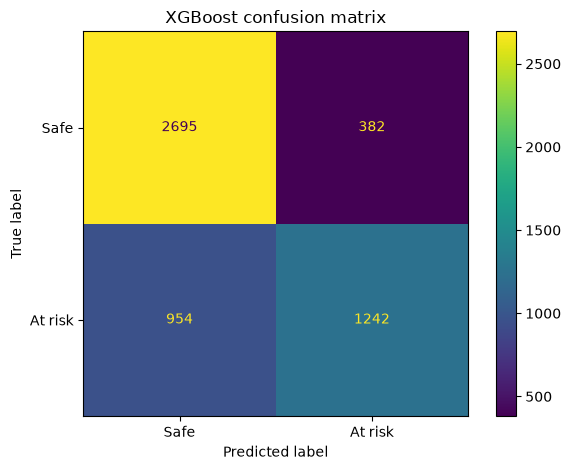

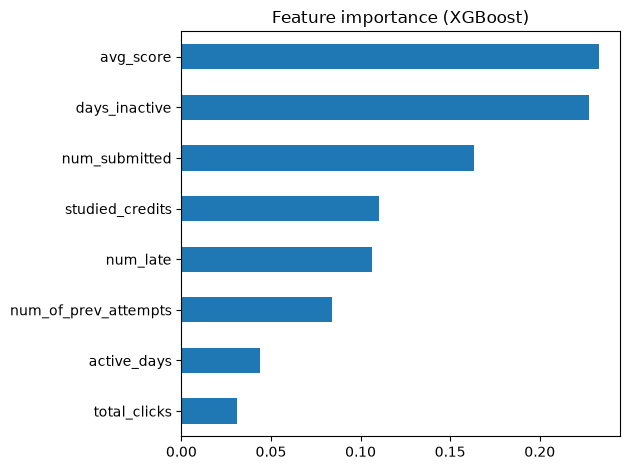

In [11]:
# Cell 11: Confusion matrix and feature importance
from sklearn.metrics import ConfusionMatrixDisplay

best = models['XGBoost']
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=['Safe', 'At risk'])
plt.title('XGBoost confusion matrix'); plt.tight_layout()
plt.savefig('figures/04_confusion_matrix.png', dpi=150)
plt.show()

pd.Series(best.feature_importances_, index=FEATURES).sort_values().plot(
    kind='barh', title='Feature importance (XGBoost)')
plt.tight_layout()
plt.savefig('figures/05_feature_importance.png', dpi=150)
plt.show()

In [12]:
# Cell 11b: Recall at the dashboard's thresholds
# predict() uses a 50% cut-off. The dashboard also flags 'Medium' students from 30%,
# so a teacher who checks Medium + High students catches many more of the at-risk ones.
prob = best.predict_proba(X_test)[:, 1]
for t in [0.5, 0.3]:
    flagged = (prob >= t).astype(int)
    print(f'risk >= {t:.0%}: recall {recall_score(y_test, flagged):.3f}, '
          f'precision {precision_score(y_test, flagged):.3f}, '
          f'students flagged {flagged.mean():.0%}')

risk >= 50%: recall 0.566, precision 0.765, students flagged 31%
risk >= 30%: recall 0.789, precision 0.607, students flagged 54%


## Phase 5: Explain with SHAP and save the model

Note: you may need to restart the kernel to use updated packages.


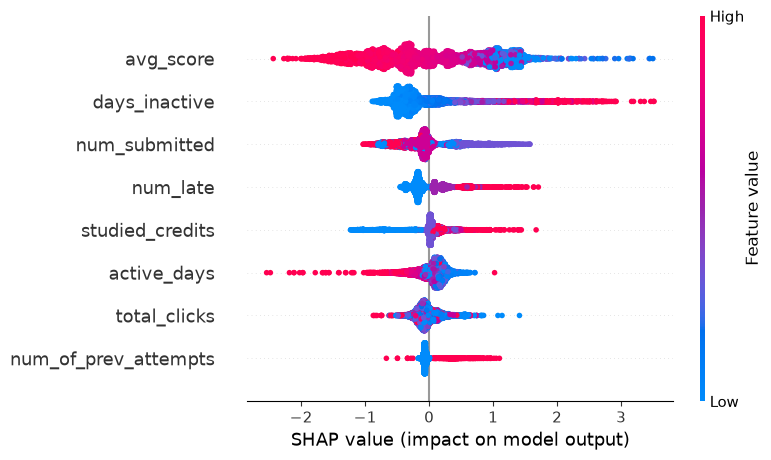

In [13]:
# Cell 12: SHAP explanation
%pip install -q shap
import shap

explainer = shap.TreeExplainer(best)
sv = explainer(X_test)
shap.plots.beeswarm(sv, show=False)
plt.tight_layout()
plt.savefig('figures/06_shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# Cell 13: Save the model and a sample class of 150 test students
import joblib

joblib.dump(best, 'model.pkl')

sample = X_test.copy()
sample.insert(0, 'student_id', df.loc[X_test.index, 'id_student'].values)
sample = sample.head(150).reset_index(drop=True)
sample.to_csv('sample_class.csv', index=False)
print(sample.shape)

if IN_COLAB:
    from google.colab import files
    files.download('model.pkl')
    files.download('sample_class.csv')

(150, 9)


In [15]:
# Cell 14: Note the versions (paste these into requirements.txt)
import sklearn, xgboost, shap, sys, numpy
print('python ', sys.version.split()[0])
print('numpy==' + numpy.__version__)
print('pandas==' + pd.__version__)
print('scikit-learn==' + sklearn.__version__)
print('xgboost==' + xgboost.__version__)
print('shap==' + shap.__version__)

python  3.12.14
numpy==2.5.4
pandas==3.1.1
scikit-learn==1.9.1
xgboost==3.4.1
shap==0.54.1
